# Análisis de emisiones de dióxido de carbono (CO₂)

## Introducción

El presente proyecto tiene como finalidad analizar el comportamiento histórico de las emisiones de dióxido de carbono (CO₂) en Colombia, utilizando datos obtenidos de la plataforma Our World in Data.

Mediante herramientas de análisis de datos en Python se realizará un proceso de exploración, limpieza, transformación y visualización de la información. Posteriormente, se implementará un modelo de regresión lineal para estudiar la tendencia de las emisiones a través del tiempo.

## Objetivo general

Analizar la evolución de las emisiones anuales de CO₂ en Colombia mediante técnicas de análisis de datos y regresión lineal.

## Objetivos específicos

- Obtener y explorar datos históricos de emisiones de CO₂.
- Realizar procesos de limpieza y transformación de datos.
- Construir visualizaciones para identificar tendencias.
- Implementar un modelo de regresión lineal.
- Interpretar los resultados obtenidos.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Bibliotecas importadas correctamente.")

Bibliotecas importadas correctamente.


## 1. Carga de datos

Se utiliza una base de datos de Our World in Data que contiene información histórica sobre las emisiones anuales de dióxido de carbono por país y región.

In [3]:
ruta = "datos/emisiones_co2.csv"

df = pd.read_csv(ruta)

print("Base de datos cargada correctamente.")
print("Dimensiones:", df.shape)

df.head()

Base de datos cargada correctamente.
Dimensiones: (30219, 4)


,Entity,Code,Year,Annual CO₂ emissions
0,Afghanistan,AFG,1949,14656.0
1,Afghanistan,AFG,1950,80608.0
2,Afghanistan,AFG,1951,87936.0
3,Afghanistan,AFG,1952,87936.0
4,Afghanistan,AFG,1953,98928.0


In [4]:
print("Columnas de la base de datos:")
print(df.columns.tolist())

print("\nInformación general:")
df.info()

print("\nPrimeros registros:")
display(df.head())

print("\nÚltimos registros:")
display(df.tail())

Columnas de la base de datos:
['Entity', 'Code', 'Year', 'Annual CO₂ emissions']

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 30219 entries, 0 to 30218
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Entity                30219 non-null  str    
 1   Code                  26889 non-null  str    
 2   Year                  30219 non-null  int64  
 3   Annual CO₂ emissions  30219 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 944.5 KB

Primeros registros:


,Entity,Code,Year,Annual CO₂ emissions
0,Afghanistan,AFG,1949,14656.0
1,Afghanistan,AFG,1950,80608.0
2,Afghanistan,AFG,1951,87936.0
3,Afghanistan,AFG,1952,87936.0
4,Afghanistan,AFG,1953,98928.0



Últimos registros:


,Entity,Code,Year,Annual CO₂ emissions
30214,Zimbabwe,ZWE,2021,10130522.0
30215,Zimbabwe,ZWE,2022,12256476.0
30216,Zimbabwe,ZWE,2023,15096099.0
30217,Zimbabwe,ZWE,2024,15206697.0
30218,Zimbabwe,ZWE,2025,17348314.0


In [5]:
colombia = df[df["Entity"] == "Colombia"].copy()

print("Registros correspondientes a Colombia:")
display(colombia.head())

print("Cantidad de registros:", len(colombia))

Registros correspondientes a Colombia:


,Entity,Code,Year,Annual CO₂ emissions
5879,Colombia,COL,1856,9721.0
5880,Colombia,COL,1857,18205.0
5881,Colombia,COL,1858,20021.0
5882,Colombia,COL,1859,5276.0
5883,Colombia,COL,1860,9308.0


Cantidad de registros: 170


## 2. Limpieza y transformación de datos

En esta etapa se identifican los valores faltantes, registros duplicados y posibles inconsistencias. Se seleccionan únicamente los datos correspondientes a Colombia para realizar el análisis.

In [6]:
# Revisar valores nulos
print("Valores nulos:")
print(colombia.isnull().sum())

# Revisar registros duplicados
print("\nRegistros duplicados:")
print(colombia.duplicated().sum())

# Identificar automáticamente la columna de emisiones
columna_emisiones = [
    c for c in colombia.columns
    if "Annual" in c and "emissions" in c
][0]

# Conservar las variables necesarias
datos = colombia[["Year", columna_emisiones]].copy()

# Renombrar las columnas
datos.columns = ["Año", "Emisiones_CO2"]

# Convertir las variables a formato numérico
datos["Año"] = pd.to_numeric(datos["Año"], errors="coerce")
datos["Emisiones_CO2"] = pd.to_numeric(
    datos["Emisiones_CO2"], errors="coerce"
)

# Eliminar valores nulos y duplicados
datos = datos.dropna()
datos = datos.drop_duplicates(subset=["Año"])

# Ordenar por año
datos = datos.sort_values("Año").reset_index(drop=True)

print("Limpieza finalizada.")
print("Registros disponibles:", len(datos))

display(datos.head())

Valores nulos:
Entity                  0
Code                    0
Year                    0
Annual CO₂ emissions    0
dtype: int64

Registros duplicados:
0
Limpieza finalizada.
Registros disponibles: 170


,Año,Emisiones_CO2
0,1856,9721.0
1,1857,18205.0
2,1858,20021.0
3,1859,5276.0
4,1860,9308.0


## 3. Análisis estadístico

Se calculan medidas estadísticas descriptivas para conocer el comportamiento de las emisiones de CO₂ en Colombia.

In [7]:
estadisticas = datos["Emisiones_CO2"].describe()

print("Estadísticas descriptivas:")
display(estadisticas)

print("Año inicial:", int(datos["Año"].min()))
print("Año final:", int(datos["Año"].max()))

print(
    "Promedio de emisiones:",
    round(datos["Emisiones_CO2"].mean(), 2),
    "toneladas"
)

print(
    "Máximo de emisiones:",
    round(datos["Emisiones_CO2"].max(), 2),
    "toneladas"
)

print(
    "Mínimo de emisiones:",
    round(datos["Emisiones_CO2"].min(), 2),
    "toneladas"
)

Estadísticas descriptivas:


count    1.700000e+02
mean     2.328111e+07
std      3.128409e+07
min      5.276000e+03
25%      8.158825e+04
50%      4.112398e+06
75%      4.634790e+07
max      1.062884e+08
Name: Emisiones_CO2, dtype: float64

Año inicial: 1856
Año final: 2025
Promedio de emisiones: 23281114.66 toneladas
Máximo de emisiones: 106288370.0 toneladas
Mínimo de emisiones: 5276.0 toneladas


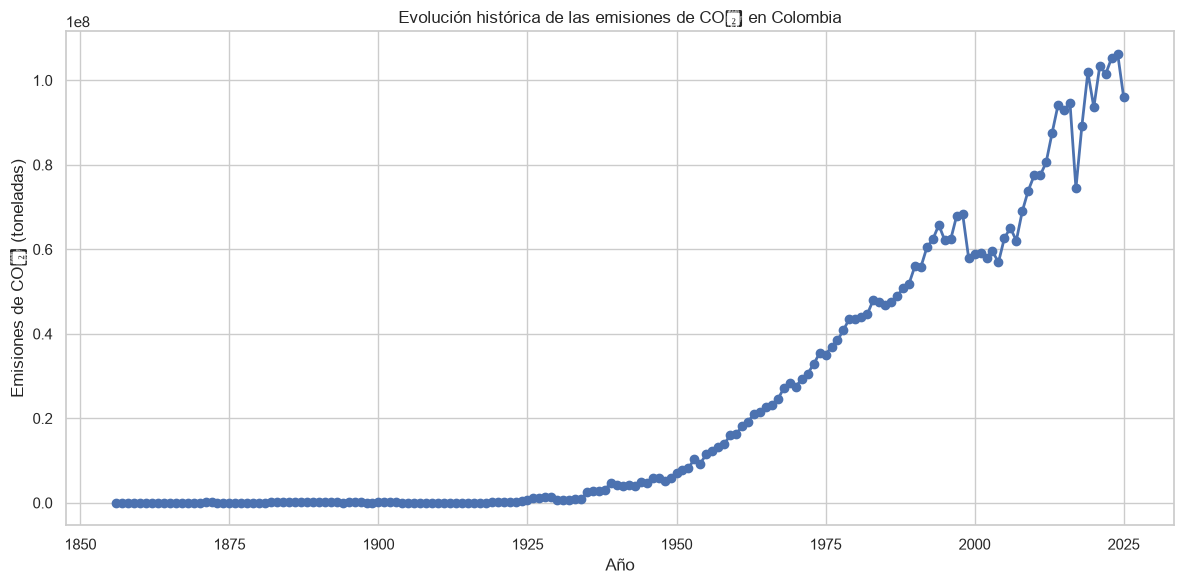

In [8]:
plt.figure(figsize=(12, 6))

plt.plot(
    datos["Año"],
    datos["Emisiones_CO2"],
    marker="o",
    linewidth=2
)

plt.title("Evolución histórica de las emisiones de CO₂ en Colombia")
plt.xlabel("Año")
plt.ylabel("Emisiones de CO₂ (toneladas)")
plt.grid(True)
plt.tight_layout()
plt.show()

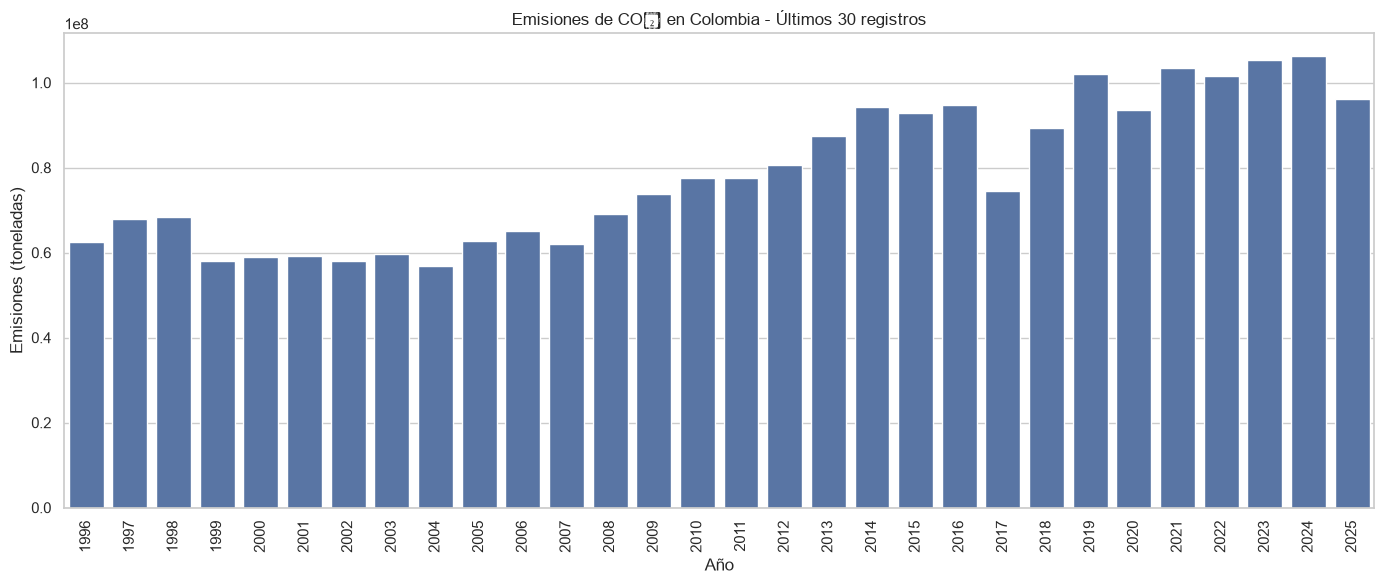

In [9]:
ultimos = datos.tail(30)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=ultimos,
    x="Año",
    y="Emisiones_CO2"
)

plt.title("Emisiones de CO₂ en Colombia - Últimos 30 registros")
plt.xlabel("Año")
plt.ylabel("Emisiones (toneladas)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

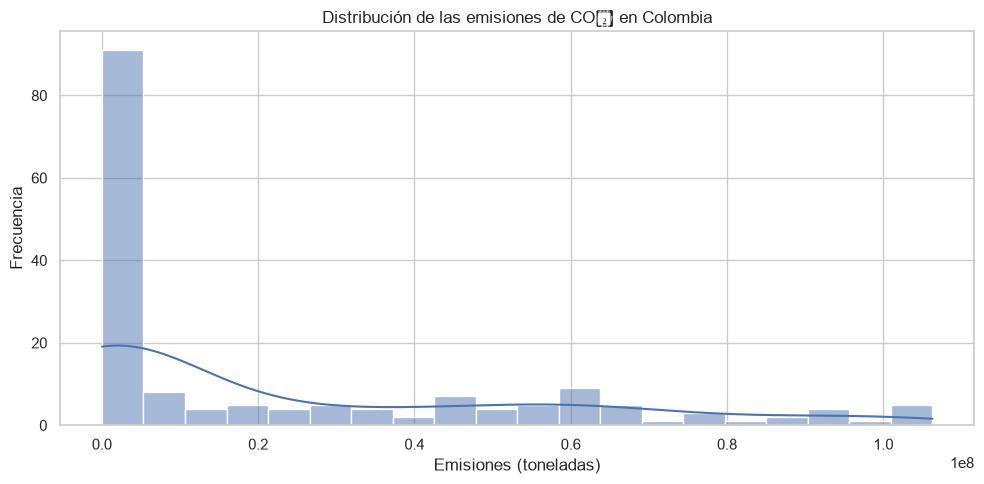

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    datos["Emisiones_CO2"],
    kde=True,
    bins=20
)

plt.title("Distribución de las emisiones de CO₂ en Colombia")
plt.xlabel("Emisiones (toneladas)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

## 4. Modelo de regresión lineal

Se implementa un modelo de regresión lineal utilizando el año como variable independiente y las emisiones de CO₂ como variable dependiente.

El objetivo es identificar la tendencia histórica de las emisiones y evaluar la capacidad del modelo para estimar sus valores.

In [11]:
# Variable independiente: año
X = datos[["Año"]]

# Variable dependiente: emisiones
y = datos["Emisiones_CO2"]

# Dividir los datos respetando el orden cronológico
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=False
)

print("Datos preparados correctamente.")
print("Datos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))

Datos preparados correctamente.
Datos de entrenamiento: 136
Datos de prueba: 34


In [12]:
modelo = LinearRegression()

modelo.fit(X_train, y_train)

print("Modelo de regresión lineal entrenado.")
print("Pendiente:", modelo.coef_[0])
print("Intercepto:", modelo.intercept_)

Modelo de regresión lineal entrenado.
Pendiente: 325976.92640518106
Intercepto: -617103478.4702188


In [13]:
predicciones = modelo.predict(X_test)

resultados = pd.DataFrame({
    "Año": X_test["Año"].values,
    "Emisiones reales": y_test.values,
    "Emisiones predichas": predicciones
})

display(resultados.head(10))

,Año,Emisiones reales,Emisiones predichas
0,1992,60461310.0,3.224256e+07
1,1993,62373510.0,3.256854e+07
2,1994,65772444.0,3.289451e+07
3,1995,62130860.0,3.322049e+07
4,1996,62387160.0,3.354647e+07
5,1997,67968184.0,3.387244e+07
6,1998,68358856.0,3.419842e+07
7,1999,57975228.0,3.452440e+07
8,2000,58938972.0,3.485037e+07
9,2001,59191148.0,3.517635e+07


In [14]:
mae = mean_absolute_error(y_test, predicciones)

mse = mean_squared_error(y_test, predicciones)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, predicciones)

print("EVALUACIÓN DEL MODELO")
print("-----------------------------")
print("Error absoluto medio (MAE):", round(mae, 2))
print("Error cuadrático medio (MSE):", round(mse, 2))
print("Raíz del error cuadrático medio (RMSE):", round(rmse, 2))
print("Coeficiente de determinación (R²):", round(r2, 4))

EVALUACIÓN DEL MODELO
-----------------------------
Error absoluto medio (MAE): 39131837.2
Error cuadrático medio (MSE): 1720579303441099.8
Raíz del error cuadrático medio (RMSE): 41479866.24
Coeficiente de determinación (R²): -5.3006


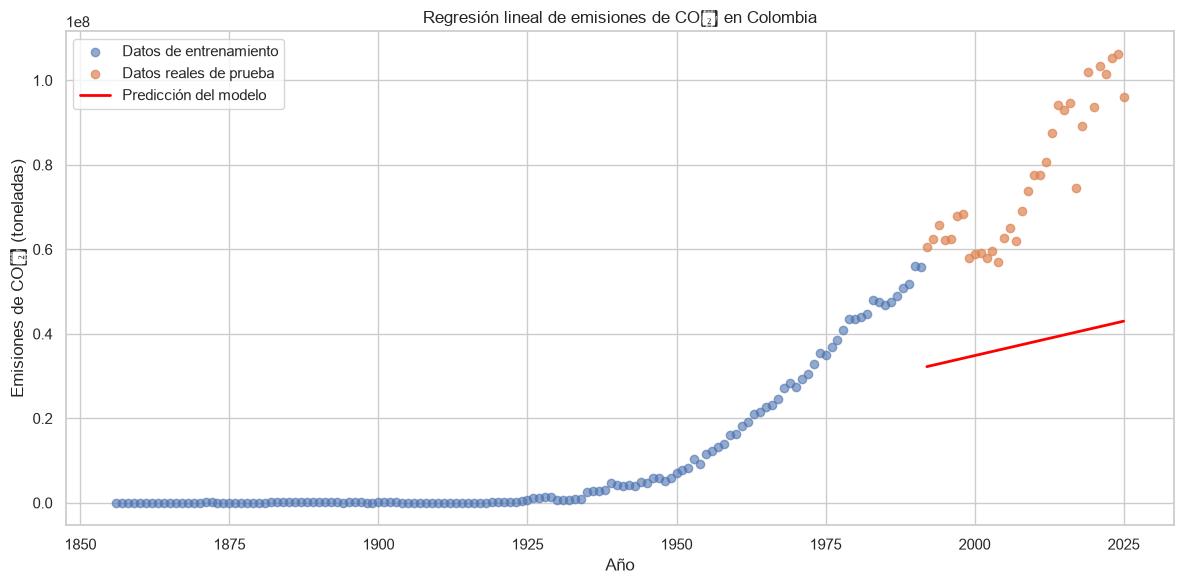

In [15]:
plt.figure(figsize=(12, 6))

plt.scatter(
    X_train["Año"],
    y_train,
    label="Datos de entrenamiento",
    alpha=0.6
)

plt.scatter(
    X_test["Año"],
    y_test,
    label="Datos reales de prueba",
    alpha=0.7
)

plt.plot(
    X_test["Año"],
    predicciones,
    color="red",
    linewidth=2,
    label="Predicción del modelo"
)

plt.title("Regresión lineal de emisiones de CO₂ en Colombia")
plt.xlabel("Año")
plt.ylabel("Emisiones de CO₂ (toneladas)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
modelo_final = LinearRegression()

modelo_final.fit(X, y)

prediccion_2030 = modelo_final.predict(
    pd.DataFrame({"Año": [2030]})
)

print(
    "Estimación de emisiones para 2030:",
    round(prediccion_2030[0], 2),
    "toneladas de CO₂"
)

Estimación de emisiones para 2030: 73073252.6 toneladas de CO₂


## 5. Interpretación de resultados

El análisis realizado permite estudiar el comportamiento histórico de las emisiones de dióxido de carbono en Colombia.

Mediante las visualizaciones se identifican los cambios en las emisiones a través de los años, permitiendo observar periodos de crecimiento y disminución.

El modelo de regresión lineal permite identificar una tendencia general y realizar estimaciones a partir de los datos históricos.

Para evaluar el modelo se utilizaron las métricas MAE, MSE, RMSE y R². Estas permiten analizar la diferencia entre los valores reales y los valores estimados.

Es importante considerar que las emisiones de CO₂ dependen de diferentes factores económicos, industriales, energéticos y ambientales, por lo que una regresión lineal basada únicamente en el año tiene limitaciones.

In [17]:
primer_valor = datos.iloc[0]["Emisiones_CO2"]
ultimo_valor = datos.iloc[-1]["Emisiones_CO2"]

cambio = ultimo_valor - primer_valor

if cambio > 0:
    tendencia = "aumentaron"
elif cambio < 0:
    tendencia = "disminuyeron"
else:
    tendencia = "se mantuvieron iguales"

print("INTERPRETACIÓN DE LOS RESULTADOS")
print("--------------------------------")

print(
    f"Entre {int(datos.iloc[0]['Año'])} y "
    f"{int(datos.iloc[-1]['Año'])}, las emisiones {tendencia}."
)

print(f"Cambio absoluto: {cambio:,.2f} toneladas.")

print(f"Coeficiente R²: {r2:.4f}")

if r2 >= 0.7:
    print("El modelo presenta un ajuste relativamente alto.")
elif r2 >= 0.3:
    print("El modelo presenta un ajuste moderado.")
else:
    print("El modelo presenta un ajuste bajo.")

print(
    "La regresión lineal debe interpretarse como una aproximación "
    "de la tendencia histórica."
)

INTERPRETACIÓN DE LOS RESULTADOS
--------------------------------
Entre 1856 y 2025, las emisiones aumentaron.
Cambio absoluto: 96,057,219.00 toneladas.
Coeficiente R²: -5.3006
El modelo presenta un ajuste bajo.
La regresión lineal debe interpretarse como una aproximación de la tendencia histórica.


## 6. Conclusiones

1. El análisis de datos permitió conocer el comportamiento histórico de las emisiones de CO₂ en Colombia mediante información obtenida de Our World in Data.

2. El proceso de limpieza permitió organizar los registros y seleccionar la información necesaria para desarrollar el proyecto.

3. Las visualizaciones facilitaron la identificación de cambios y tendencias en las emisiones a través del tiempo.

4. La implementación de la regresión lineal permitió estudiar la relación entre los años y las emisiones de CO₂, además de evaluar el comportamiento del modelo mediante diferentes métricas estadísticas.

5. Finalmente, este proyecto permitió aplicar herramientas de Python para el análisis de datos y comprender la importancia de utilizar información basada en evidencia para estudiar problemáticas ambientales.

In [18]:
import os

os.makedirs("resultados", exist_ok=True)

# Guardar los datos limpios
datos.to_csv(
    "resultados/emisiones_colombia_limpias.csv",
    index=False
)

# Guardar las predicciones
resultados.to_csv(
    "resultados/predicciones_regresion.csv",
    index=False
)

print("Archivos guardados correctamente.")

Archivos guardados correctamente.


## 7. Referencias bibliográficas

Our World in Data. (2026). Annual CO₂ emissions. Global Carbon Budget. https://ourworldindata.org/grapher/annual-co2-emissions-per-country

Our World in Data. (2026). CO₂ and greenhouse gas emissions. https://ourworldindata.org/co2-and-greenhouse-gas-emissions

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825–2830.